In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import importlib.metadata

print("Pandas:", importlib.metadata.version("pandas"))
print("NumPy:", importlib.metadata.version("numpy"))
print("Libraries imported successfully!")

Pandas: 3.1.1
NumPy: 2.5.4
Libraries imported successfully!


In [6]:
df = pd.read_excel("Car_price_prediction.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [8]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 301
Number of Columns: 9


In [9]:
df.columns

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms',
       'Fuel_Type', 'Selling_type', 'Transmission', 'Owner'],
      dtype='str')

In [10]:
df.isnull().sum()

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     1
Transmission     0
Owner            0
dtype: int64

In [11]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 2


In [12]:
df.drop_duplicates(inplace=True)

print("Duplicate rows removed successfully!")

Duplicate rows removed successfully!


C:\Users\mayur\AppData\Local\Temp\ipykernel_9120\2699512638.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 299 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       299 non-null    object 
 1   Year           299 non-null    int64  
 2   Selling_Price  299 non-null    float64
 3   Present_Price  299 non-null    float64
 4   Driven_kms     299 non-null    int64  
 5   Fuel_Type      299 non-null    str    
 6   Selling_type   298 non-null    str    
 7   Transmission   299 non-null    str    
 8   Owner          299 non-null    int64  
dtypes: float64(2), int64(3), object(1), str(3)
memory usage: 23.4+ KB


In [14]:
df.describe()

,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,299.000000,299.000000,299.000000,299.000000,299.000000
mean,2013.615385,4.589632,7.541037,36916.752508,0.043478
std,2.896868,4.984240,8.566332,39015.170352,0.248720
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.850000,1.200000,15000.000000,0.000000
50%,2014.000000,3.510000,6.100000,32000.000000,0.000000
75%,2016.000000,6.000000,9.840000,48883.500000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


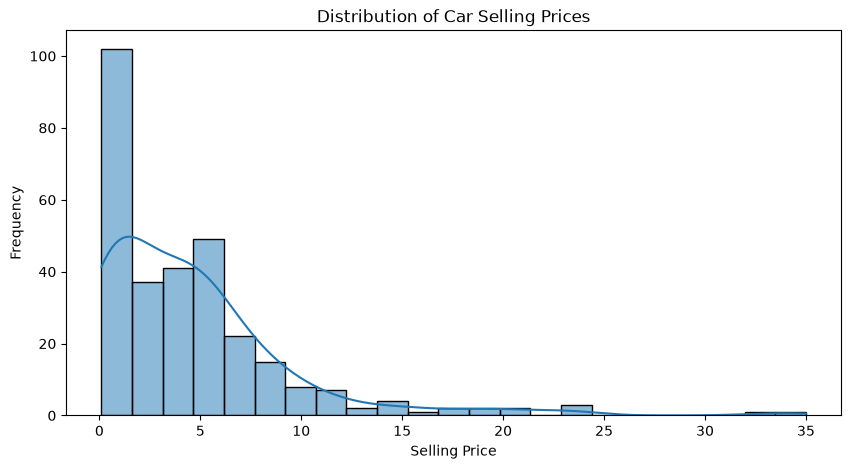

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(df['Selling_Price'], kde=True)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")

plt.show()

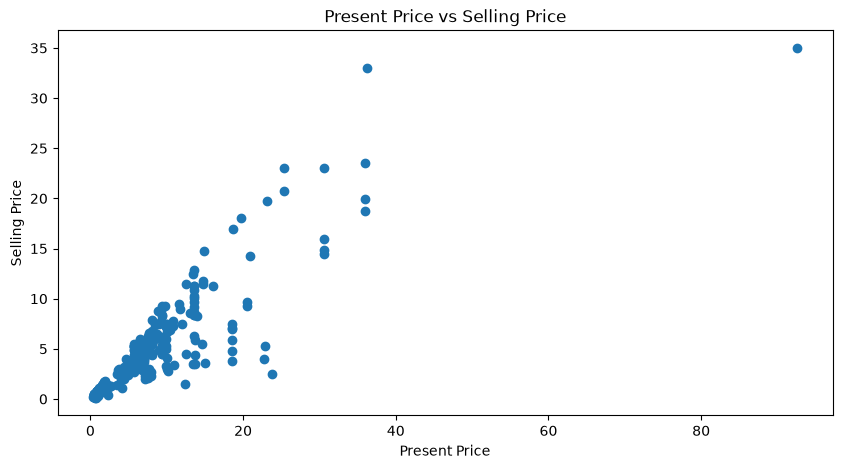

In [16]:
plt.figure(figsize=(10, 5))

plt.scatter(df['Present_Price'], df['Selling_Price'])

plt.title("Present Price vs Selling Price")
plt.xlabel("Present Price")
plt.ylabel("Selling Price")

plt.show()

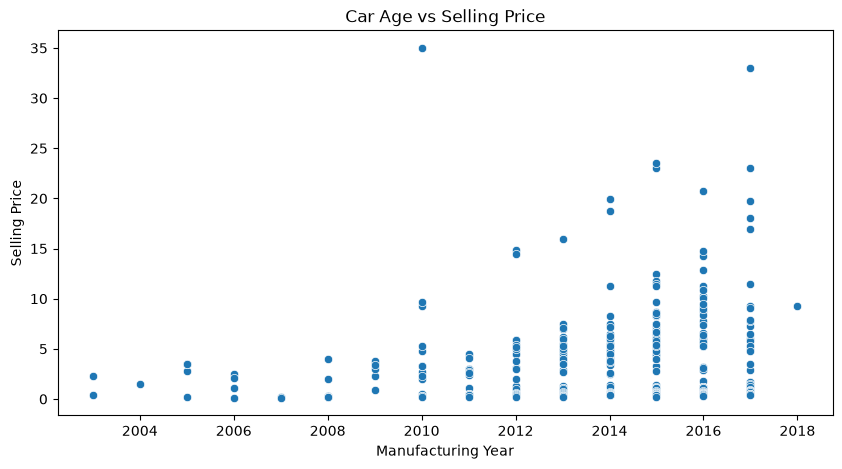

In [17]:
plt.figure(figsize=(10, 5))

sns.scatterplot(x='Year', y='Selling_Price', data=df)

plt.title("Car Age vs Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price")

plt.show()

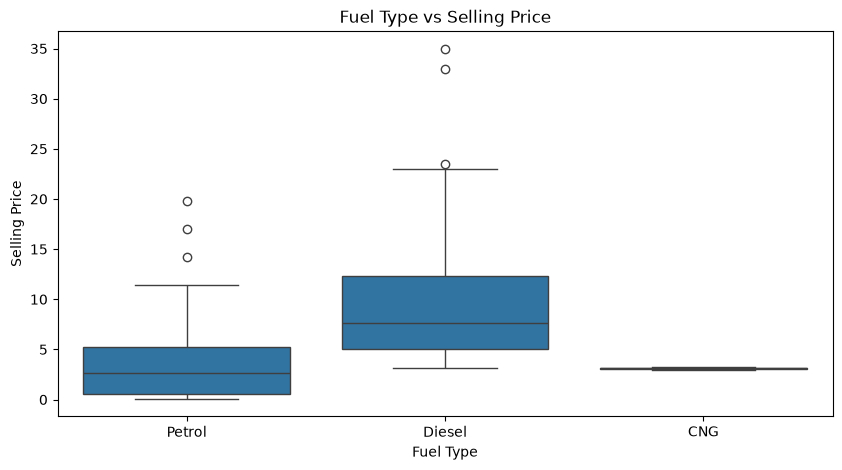

In [18]:
plt.figure(figsize=(10, 5))

sns.boxplot(x='Fuel_Type', y='Selling_Price', data=df)

plt.title("Fuel Type vs Selling Price")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")

plt.show()

In [19]:
categorical_cols = df.select_dtypes(include=['object']).columns

print("Categorical Columns:")
print(categorical_cols)

Categorical Columns:
Index(['Car_Name', 'Fuel_Type', 'Selling_type', 'Transmission'], dtype='str')


C:\Users\mayur\AppData\Local\Temp\ipykernel_9120\3301230942.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns


In [20]:
df = pd.get_dummies(df, drop_first=True)

print("Categorical data converted successfully!")

Categorical data converted successfully!


In [21]:
df = pd.read_excel("Car_price_prediction.xlsx")

df.drop('Car_Name', axis=1, inplace=True)

df = pd.get_dummies(df, drop_first=True)

print("Unnecessary column removed successfully!")

Unnecessary column removed successfully!


C:\Users\mayur\AppData\Local\Temp\ipykernel_9120\3977154331.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('Car_Name', axis=1, inplace=True)


In [22]:
X = df.drop('Selling_Price', axis=1)

y = df['Selling_Price']

print("Features and Target separated successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)

Features and Target separated successfully!
X shape: (301, 8)
y shape: (301,)


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training and Testing data created successfully!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Training and Testing data created successfully!
X_train: (240, 8)
X_test: (61, 8)
y_train: (240,)
y_test: (61,)


In [24]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [25]:
y_pred = model.predict(X_test)

print("Car Price Predictions:")
print(y_pred[:10])

Car Price Predictions:
[ 2.95778026  8.16560991  6.44889065 -1.41672922  9.08451717  7.40735375
  1.34306095  0.85160472  1.36987061  7.48271566]


In [26]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,0.35,2.957780
1,10.11,8.165610
2,4.95,6.448891
3,0.15,-1.416729
4,6.95,9.084517
5,7.45,7.407354
6,1.10,1.343061
7,0.50,0.851605
8,0.45,1.369871
9,6.00,7.482716


In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 1.215122355966407
Mean Squared Error: 3.4756805283052206
Root Mean Squared Error: 1.8643177112030076
R2 Score: 0.8491168945487897


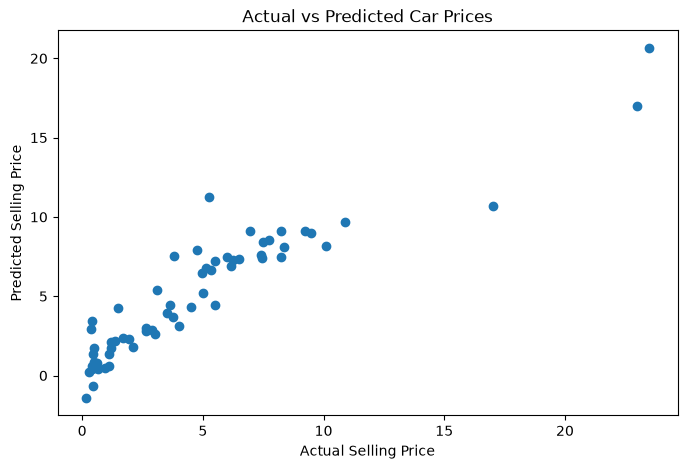

In [28]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

In [29]:
print("Dataset Shape:", df.shape)
print("Model:", model)
print("R2 Score:", r2)
print("Task 3 Completed Successfully!")

Dataset Shape: (301, 9)
Model: LinearRegression()
R2 Score: 0.8491168945487897
Task 3 Completed Successfully!
